# Manutenção Preditiva na Indústria 4.0

**Projeto Avaliativo — Módulo 1: Fundamentos de Dados, Programação e Análise Preditiva com Python**

Este notebook apresenta o desenvolvimento passo a passo de um Pipeline Preditivo para prever falhas mecânicas em equipamentos industriais (`falha_maquina = 1` para falha e `falha_maquina = 0` para funcionamento normal), utilizando dados coletados por sensores.

---
## Fase 1: Análise Exploratória (EDA)

Nesta primeira etapa, vamos carregar o conjunto de dados a partir da pasta `../data`, verificar suas dimensões (quantidade de linhas e colunas), os tipos de dados de cada variável, o resumo estatístico descritivo e visualizar o comportamento dos dados por meio de 3 gráficos analíticos.

In [1]:
# Importando as bibliotecas básicas para análise de dados e gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregando a base de dados utilizando caminho relativo
df = pd.read_csv('../data/manutencao_preditiva.csv')

# Exibindo as 5 primeiras linhas da tabela
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


In [2]:
# Apresentando as dimensões do dataset (linhas e colunas) e os tipos de dados
print("Dimensões do dataset (linhas, colunas):", df.shape)
print("\nTipos de dados das variáveis:")
print(df.dtypes)

Dimensões do dataset (linhas, colunas): (10000, 14)

Tipos de dados das variáveis:
udi                          int64
id_produto                     str
tipo                           str
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object


In [3]:
# Resumo estatístico descritivo das colunas numéricas
df.describe()

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### Gráfico 1: Taxa de Desbalanceamento da Variável Alvo (`falha_maquina`)

Contagem de registros por classe (0 = Normal, 1 = Falha):
falha_maquina
0    9661
1     339
Name: count, dtype: int64

Porcentagem de cada classe (%):
falha_maquina
0    96.61
1     3.39
Name: proportion, dtype: float64


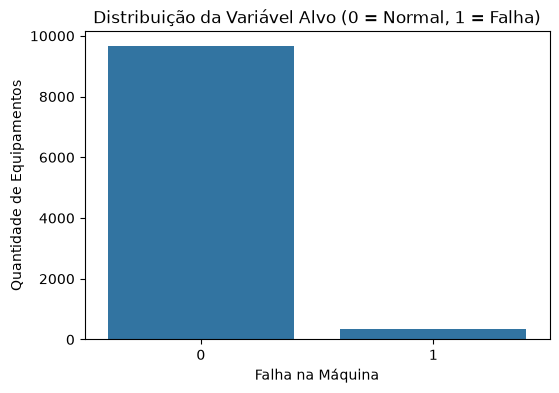

In [4]:
# Verificando a quantidade e a porcentagem de cada classe da variável alvo
print("Contagem de registros por classe (0 = Normal, 1 = Falha):")
print(df['falha_maquina'].value_counts())

print("\nPorcentagem de cada classe (%):")
print(df['falha_maquina'].value_counts(normalize=True) * 100)

# Plotando o gráfico de barras da variável alvo
plt.figure(figsize=(6, 4))
sns.countplot(x='falha_maquina', data=df)
plt.title('Distribuição da Variável Alvo (0 = Normal, 1 = Falha)')
plt.xlabel('Falha na Máquina')
plt.ylabel('Quantidade de Equipamentos')
plt.show()

### Gráfico 2: Histograma de Distribuição das Variáveis Preditoras

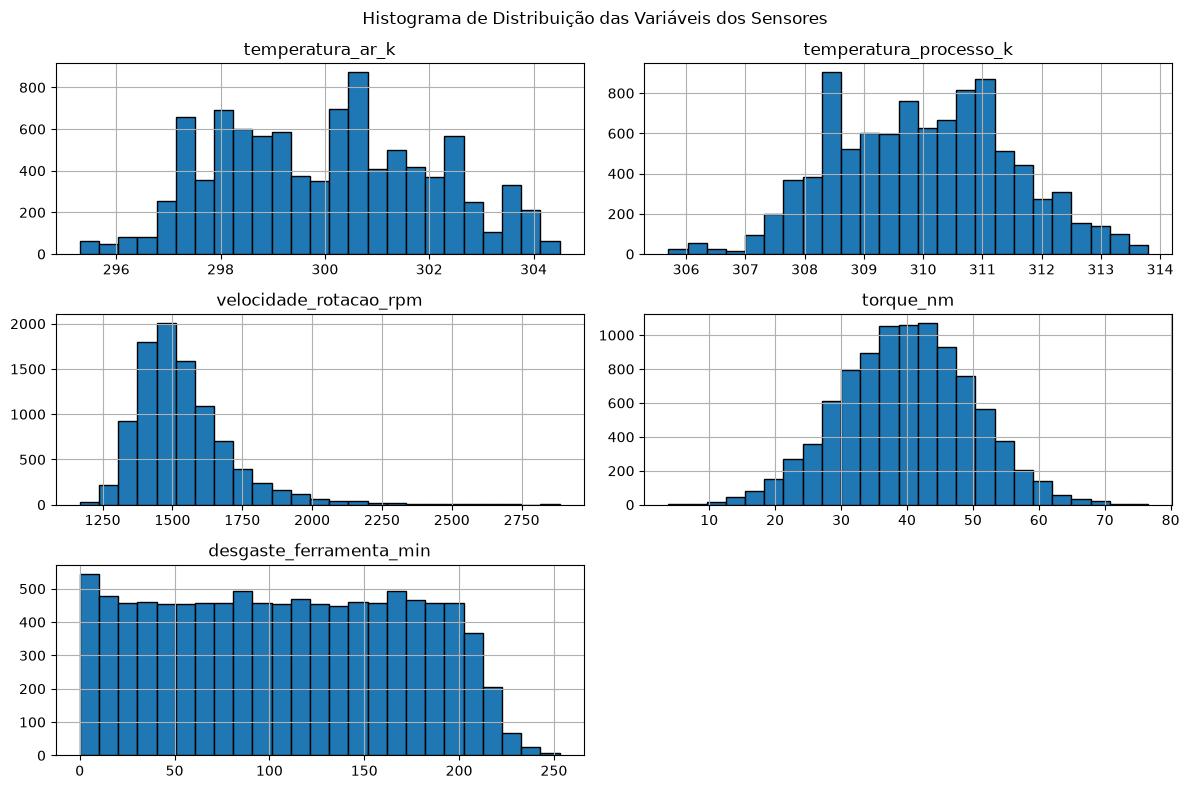

In [5]:
# Selecionando as variáveis numéricas contínuas medidas pelos sensores
colunas_sensores = [
    'temperatura_ar_k',
    'temperatura_processo_k',
    'velocidade_rotacao_rpm',
    'torque_nm',
    'desgaste_ferramenta_min'
]

# Plotando o histograma para observar a distribuição de cada sensor
df[colunas_sensores].hist(bins=25, figsize=(12, 8), edgecolor='black')
plt.suptitle('Histograma de Distribuição das Variáveis dos Sensores')
plt.tight_layout()
plt.show()

### Gráfico 3: Mapa de Calor com a Correlação de Pearson

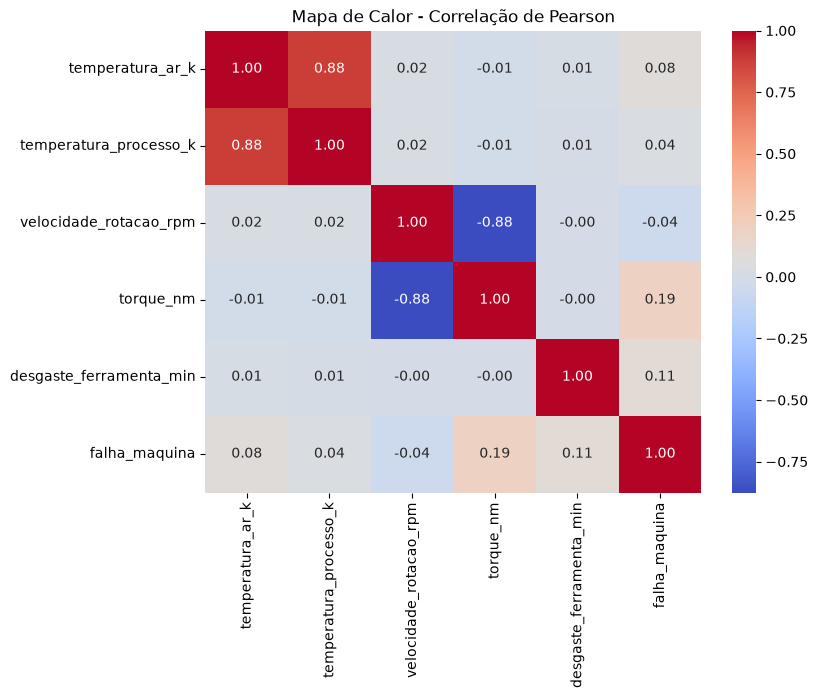

In [6]:
# Selecionando as colunas dos sensores junto com a variável alvo para calcular a correlação
colunas_correlacao = [
    'temperatura_ar_k',
    'temperatura_processo_k',
    'velocidade_rotacao_rpm',
    'torque_nm',
    'desgaste_ferramenta_min',
    'falha_maquina'
]

matriz_correlacao = df[colunas_correlacao].corr()

# Plotando o mapa de calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Mapa de Calor - Correlação de Pearson')
plt.show()

### Análise dos Valores Numéricos e Padrões Identificados na EDA

A partir das tabelas estatísticas e dos 3 gráficos gerados acima, identificamos os seguintes pontos que direcionam nossa estratégia de modelagem:

1. **Dimensões e Dados Ausentes:** O dataset possui **10.000 linhas e 14 colunas**. Observando a linha `count` do método `.describe()`, notamos que as variáveis `temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm` possuem apenas `9.500` registros preenchidos. Isso mostra que existem **500 valores nulos** nessas colunas que precisarão ser tratados na Fase 2 antes do treinamento dos modelos.
2. **Desbalanceamento Severo da Variável Alvo (Gráfico 1):** A variável alvo `falha_maquina` é altamente desbalanceada: **96,61% (9.661 registros)** representam máquinas em funcionamento normal (`0`) e apenas **3,39% (339 registros)** representam falhas mecânicas (`1`). Se treinarmos os modelos diretamente assim, eles tenderão a chutar sempre `0`. Por isso, na Fase 4 precisaremos dividir os dados com estratificação (`stratify=y`) e aplicar o balanceamento (SMOTE) nos dados de treino.
3. **Comportamento e Escala das Variáveis (Gráfico 2):** Nos histogramas, `temperatura_ar_k`, `temperatura_processo_k` e `torque_nm` apresentam formato próximo ao de um sino (distribuição simétrica), enquanto `velocidade_rotacao_rpm` possui forte assimetria para a direita (cauda longa chegando até `2.886 RPM`), indicando a presença de valores extremos (*outliers*). Além disso, as unidades de medida possuem escalas muito diferentes (ex: rotação na casa de `1.500 RPM` contra torque em torno de `40 Nm`), o que torna obrigatório o uso do `StandardScaler` na Fase 5 para o algoritmo KNN.
4. **Relações Físicas na Correlação de Pearson (Gráfico 3):** O mapa de calor revela uma correlação positiva muito forte (**0,88**) entre `temperatura_ar_k` e `temperatura_processo_k`, e uma correlação negativa muito forte (**-0,88**) entre `velocidade_rotacao_rpm` e `torque_nm`. Na física dos motores, rotação e torque atuam juntos para gerar potência mecânica, o que fundamenta a criação da nova coluna `potencia` na Fase 3.